In [21]:
import pandas as pd
import numpy as np

# ============================================================
# 30% MISSINGNESS DATASET
# ============================================================

input_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_missing_30pct.csv"

df_5 = pd.read_csv(input_path)

print("Shape:", df_5.shape)
print("\nMissing values in pollutant columns:")

pollutants = [
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3"
]

print(df_5[pollutants].isnull().sum())

Shape: (8768, 22)

Missing values in pollutant columns:
pm25    2630
pm10    2630
no2     2630
so2     2630
co      2630
o3      2630
dtype: int64


In [22]:
original_30pct = df_5.copy()

In [23]:
df_5

,datetime,date,year,month,day,hour,day_of_week,is_weekend,pm25,pm10,...,co,o3,temperature,humidity,wind_speed,visibility,aqi,season_post_monsoon,season_summer,season_winter
0,2020-01-01 06:00:00,2020-01-01,2020,1,1,6,2,0,327.0,596.1,...,5.13,15.2,9.9,100,2.2,1.3,500,0,0,1
1,2020-01-01 12:00:00,2020-01-01,2020,1,1,12,2,0,231.1,436.6,...,3.92,NaN,17.2,46,9.9,2.6,408,0,0,1
2,2020-01-01 18:00:00,2020-01-01,2020,1,1,18,2,0,271.6,483.2,...,NaN,25.6,14.1,64,6.6,2.5,466,0,0,1
3,2020-01-01 23:00:00,2020-01-01,2020,1,1,23,2,0,324.8,655.0,...,NaN,17.5,12.5,45,4.4,0.7,500,0,0,1
4,2020-01-02 06:00:00,2020-01-02,2020,1,2,6,3,0,350.2,NaN,...,4.44,15.3,6.3,100,2.4,0.8,500,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8763,2025-12-30 23:00:00,2025-12-30,2025,12,30,23,1,0,272.5,NaN,...,4.77,NaN,14.3,49,6.8,2.9,500,0,0,1
8764,2025-12-31 06:00:00,2025-12-31,2025,12,31,6,2,0,NaN,666.1,...,5.50,16.8,8.2,100,2.5,0.8,500,0,0,1
8765,2025-12-31 12:00:00,2025-12-31,2025,12,31,12,2,0,183.5,NaN,...,NaN,NaN,21.3,63,8.8,3.1,349,0,0,1
8766,2025-12-31 18:00:00,2025-12-31,2025,12,31,18,2,0,260.0,450.7,...,5.53,25.1,16.4,61,5.9,2.9,426,0,0,1


In [24]:
df_mean = original_30pct.copy()

for column in pollutants:
    mean_value = df_mean[column].mean()
    df_mean[column] = df_mean[column].fillna(mean_value)

print("Remaining missing values:")
print(df_mean[pollutants].isnull().sum())

Remaining missing values:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64


In [25]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_Mean.csv"

df_mean.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_Mean.csv


In [26]:
# ============================================================
# VERIFY 30% MEAN IMPUTATION
# ============================================================

# 1. Shape comparison
print("Original 30% dataset shape :", original_30pct.shape)
print("Mean-imputed dataset shape:", df_mean.shape)

# 2. Check missing values in pollutants
print("\nMissing values after Mean Imputation:")
print(df_mean[pollutants].isnull().sum())

# 3. Check total missing values
print("\nTotal missing values in entire dataset:")
print(df_mean.isnull().sum().sum())

# 4. Check that row count is unchanged
print("\nRows unchanged:", len(original_30pct) == len(df_mean))

# 5. Check imputed values
print("\nMean values used for imputation:")
for column in pollutants:
    print(f"{column}: {original_30pct[column].mean()}")

# 6. Basic statistics after imputation
print("\nPollutant statistics after Mean Imputation:")
display(df_mean[pollutants].describe())

Original 30% dataset shape : (8768, 22)
Mean-imputed dataset shape: (8768, 22)

Missing values after Mean Imputation:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values in entire dataset:
0

Rows unchanged: True

Mean values used for imputation:
pm25: 165.36917562724014
pm10: 307.7128869338547
no2: 61.50086347344412
so2: 13.244020853698274
co: 2.678139459107201
o3: 27.685793418051485

Pollutant statistics after Mean Imputation:


,pm25,pm10,no2,so2,co,o3
count,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000
mean,165.369176,307.712887,61.500863,13.244021,2.678139,27.685793
std,150.616002,280.069281,57.532945,11.654072,2.516018,11.258028
min,15.000000,24.000000,8.000000,4.000000,0.300000,12.000000
25%,62.300000,118.200000,22.500000,4.900000,0.980000,21.200000
50%,165.369176,307.712887,61.500863,13.244021,2.678139,27.685793
75%,172.400000,316.025000,61.500863,13.244021,2.678139,28.700000
max,900.000000,1975.600000,564.400000,93.400000,22.490000,84.000000


In [27]:
# ============================================================
# 30% MEDIAN IMPUTATION
# ============================================================

df_median = original_30pct.copy()

for column in pollutants:
    median_value = df_median[column].median()
    df_median[column] = df_median[column].fillna(median_value)

print("Missing values after Median Imputation:")
print(df_median[pollutants].isnull().sum())

Missing values after Median Imputation:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64


In [28]:
print("Median values used for imputation:")

for column in pollutants:
    print(f"{column}: {original_30pct[column].median()}")

Median values used for imputation:
pm25: 88.75
pm10: 167.6
no2: 33.349999999999994
so2: 7.1
co: 1.46
o3: 23.6


In [29]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_Median.csv"

df_median.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_Median.csv


In [30]:
print("Shape:", df_median.shape)

print("\nMissing values:")
print(df_median[pollutants].isnull().sum())

print("\nTotal missing values:")
print(df_median.isnull().sum().sum())

print("\nStatistics:")
display(df_median[pollutants].describe())

Shape: (8768, 22)

Missing values:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values:
0

Statistics:


,pm25,pm10,no2,so2,co,o3
count,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000
mean,142.386918,265.685413,53.056889,11.401095,2.312753,26.460242
std,154.654512,287.335265,58.961540,11.989366,2.577201,11.412667
min,15.000000,24.000000,8.000000,4.000000,0.300000,12.000000
25%,62.300000,118.200000,22.500000,4.900000,0.980000,21.200000
50%,88.750000,167.600000,33.350000,7.100000,1.460000,23.600000
75%,172.400000,316.025000,60.500000,12.700000,2.640000,28.700000
max,900.000000,1975.600000,564.400000,93.400000,22.490000,84.000000


In [31]:
# ============================================================
# 30% FORWARD FILL IMPUTATION
# ============================================================

df_ffill = original_30pct.copy()

for column in pollutants:
    df_ffill[column] = df_ffill[column].ffill()

print("Missing values after Forward Fill:")
print(df_ffill[pollutants].isnull().sum())

Missing values after Forward Fill:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64


In [32]:
print("Total missing values in entire dataset:")
print(df_ffill.isnull().sum().sum())

Total missing values in entire dataset:
0


In [33]:
print("\nFirst rows of pollutant columns:")
display(df_ffill[pollutants].head(10))


First rows of pollutant columns:


,pm25,pm10,no2,so2,co,o3
0,327.0,596.1,111.2,22.6,5.13,15.2
1,231.1,436.6,95.0,18.3,3.92,15.2
2,271.6,483.2,128.4,18.3,3.92,25.6
3,324.8,655.0,104.1,27.3,3.92,17.5
4,350.2,655.0,125.5,20.4,4.44,15.3
5,203.6,655.0,125.5,20.5,4.44,15.3
6,276.8,655.0,125.5,17.4,5.95,22.3
7,276.8,655.0,125.5,19.9,4.04,26.6
8,315.5,687.8,125.5,18.0,4.04,16.2
9,184.4,313.9,69.2,17.3,2.64,34.4


In [34]:
df_ffill[pollutants] = df_ffill[pollutants].ffill().bfill()

In [35]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_ForwardFill.csv"

df_ffill.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_ForwardFill.csv


In [36]:
# ============================================================
# VERIFY 30% FORWARD FILL DATASET
# ============================================================

path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_ForwardFill.csv"

df_ffill = pd.read_csv(path)

print("Shape:", df_ffill.shape)

print("\nMissing values in pollutant columns:")
print(df_ffill[pollutants].isnull().sum())

print("\nTotal missing values in entire dataset:")
print(df_ffill.isnull().sum().sum())

print("\nFirst 5 pollutant rows:")
display(df_ffill[pollutants].head())

print("\nFirst-row O3 value:", df_ffill.loc[0, "o3"])

Shape: (8768, 22)

Missing values in pollutant columns:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values in entire dataset:
0

First 5 pollutant rows:


,pm25,pm10,no2,so2,co,o3
0,327.0,596.1,111.2,22.6,5.13,15.2
1,231.1,436.6,95.0,18.3,3.92,15.2
2,271.6,483.2,128.4,18.3,3.92,25.6
3,324.8,655.0,104.1,27.3,3.92,17.5
4,350.2,655.0,125.5,20.4,4.44,15.3



First-row O3 value: 15.2


In [37]:
# ============================================================
# 30% LINEAR INTERPOLATION
# ============================================================

df_linear = original_30pct.copy()

for column in pollutants:
    df_linear[column] = df_linear[column].interpolate(
        method="linear"
    )

print("Missing values after Linear Interpolation:")
print(df_linear[pollutants].isnull().sum())

print("\nTotal missing values:")
print(df_linear.isnull().sum().sum())

Missing values after Linear Interpolation:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values:
0


In [38]:
display(df_linear[pollutants].head(5))

,pm25,pm10,no2,so2,co,o3
0,327.0,596.10,111.2,22.6,5.130000,15.2
1,231.1,436.60,95.0,18.3,3.920000,20.4
2,271.6,483.20,128.4,22.8,4.093333,25.6
3,324.8,655.00,104.1,27.3,4.266667,17.5
4,350.2,661.56,125.5,20.4,4.440000,15.3


In [39]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_LinearInterpolation.csv"

df_linear.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_LinearInterpolation.csv


In [40]:
# ============================================================
# 30% KNN IMPUTATION
# ============================================================

from sklearn.impute import KNNImputer

df_knn = original_30pct.copy()

# KNN works only on numerical columns.
# We impute only the six pollutant columns.
knn_imputer = KNNImputer(n_neighbors=5)

df_knn[pollutants] = knn_imputer.fit_transform(
    df_knn[pollutants]
)

print("Missing values after KNN:")
print(df_knn[pollutants].isnull().sum())

print("\nTotal missing values:")
print(df_knn.isnull().sum().sum())

Missing values after KNN:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values:
0


In [41]:
# Save KNN-imputed dataset
knn_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_KNN.csv"

df_knn.to_csv(
    knn_path,
    index=False
)

print("KNN dataset saved:")
print(knn_path)

KNN dataset saved:
/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_KNN.csv


In [42]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import os

# ==============================
# 1. File paths
# ==============================

input_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_missing_30pct.csv"

output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_XGBoost.csv"


# ==============================
# 2. Load dataset
# ==============================

df = pd.read_csv(input_path)

print("Dataset shape:", df.shape)


# ==============================
# 3. Pollutant columns
# ==============================

pollutants = [
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3"
]


# ==============================
# 4. Convert day_of_week
#    ONLY for this experiment
# ==============================

day_map = {
    "Monday": 0,
    "Tuesday": 1,
    "Wednesday": 2,
    "Thursday": 3,
    "Friday": 4,
    "Saturday": 5,
    "Sunday": 6
}

# If values are weekday names
if df["day_of_week"].dtype == "object":
    df["day_of_week"] = (
        df["day_of_week"]
        .astype(str)
        .str.strip()
        .str.title()
        .map(day_map)
    )

# If values are numeric strings, convert them
df["day_of_week"] = pd.to_numeric(
    df["day_of_week"],
    errors="coerce"
)


# ==============================
# 5. Features for XGBoost
# ==============================

# Do NOT use datetime/date/station-type text columns
exclude_columns = [
    "datetime",
    "date",
    "aqi"
]

# We will predict each pollutant separately
feature_columns = [
    col for col in df.columns
    if col not in exclude_columns + pollutants
]

print("\nFeatures used:")
print(feature_columns)


# ==============================
# 6. Check remaining non-numeric
# ==============================

print("\nNon-numeric columns:")

for col in feature_columns:
    if not pd.api.types.is_numeric_dtype(df[col]):
        print(col, df[col].dtype)


# ==============================
# 7. Make sure features are numeric
# ==============================

for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# ==============================
# 8. XGBoost parameters
# ==============================

model_params = {
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist",
    "device": "cuda"
}

# ==============================
# 9. Impute each pollutant
# ==============================

for target in pollutants:

    print("\n" + "=" * 60)
    print("Processing:", target)
    print("=" * 60)

    # Rows where target is available
    train_mask = df[target].notna()

    # Rows where target is missing
    missing_mask = df[target].isna()

    print("Training rows:", train_mask.sum())
    print("Missing rows:", missing_mask.sum())

    if missing_mask.sum() == 0:
        print("No missing values. Skipping.")
        continue

    # Training data
    X_train = df.loc[train_mask, feature_columns].copy()
    y_train = df.loc[train_mask, target].copy()

    # Rows to predict
    X_missing = df.loc[missing_mask, feature_columns].copy()

    # --------------------------------
    # Handle missing feature values
    # --------------------------------
    # XGBoost can handle NaN values natively,
    # so no separate imputation is required.

    # --------------------------------
    # Train XGBoost
    # --------------------------------

    model = XGBRegressor(**model_params)

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------
    # Predict missing values
    # --------------------------------

    predictions = model.predict(X_missing)

    # --------------------------------
    # Fill missing values
    # --------------------------------

    df.loc[missing_mask, target] = predictions

    print(
        "Filled:",
        len(predictions),
        "values"
    )


# ==============================
# 10. Save result
# ==============================

df.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 60)
print("XGBoost imputation completed.")
print("Saved to:")
print(output_path)
print("=" * 60)


# ==============================
# 11. Verify missing values
# ==============================

print("\nRemaining missing values:")

print(
    df[pollutants]
    .isna()
    .sum()
)

print("\nTotal missing pollutant values:",
      df[pollutants].isna().sum().sum())

Dataset shape: (8768, 22)

Features used:
['year', 'month', 'day', 'hour', 'day_of_week', 'is_weekend', 'temperature', 'humidity', 'wind_speed', 'visibility', 'season_post_monsoon', 'season_summer', 'season_winter']

Non-numeric columns:

Processing: pm25
Training rows: 6138
Missing rows: 2630


/home/dhruv/tf-gpu-313/lib/python3.13/site-packages/xgboost/core.py:569: UserWarning: [09:35:00] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Filled: 2630 values

Processing: pm10
Training rows: 6138
Missing rows: 2630
Filled: 2630 values

Processing: no2
Training rows: 6138
Missing rows: 2630
Filled: 2630 values

Processing: so2
Training rows: 6138
Missing rows: 2630
Filled: 2630 values

Processing: co
Training rows: 6138
Missing rows: 2630
Filled: 2630 values

Processing: o3
Training rows: 6138
Missing rows: 2630
Filled: 2630 values

XGBoost imputation completed.
Saved to:
/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_30pct_XGBoost.csv

Remaining missing values:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing pollutant values: 0


In [43]:
# ============================================================
# 0% BASELINE — 2020–2024 TRAIN / 2025 TEST
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# Load master dataset
df = pd.read_csv(
    f"{DATA_DIR}/aqi.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# Target
target = "aqi"

# Features
exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# ------------------------------------------------------------
# 2020–2024 → Training
# 2025 → Testing
# ------------------------------------------------------------

train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("=" * 55)
print("0% BASELINE — YEAR-BASED SPLIT")
print("=" * 55)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining period:")
print(df.loc[train_mask, "datetime"].min())
print("to")
print(df.loc[train_mask, "datetime"].max())

print("\nTesting period:")
print(df.loc[test_mask, "datetime"].min())
print("to")
print(df.loc[test_mask, "datetime"].max())

print("\nNumber of features:", len(features))
print("Missing values:", X.isna().sum().sum())

0% BASELINE — YEAR-BASED SPLIT
Training samples: 7308
Testing samples : 1460

Training period:
2020-01-01 06:00:00
to
2024-12-31 23:00:00

Testing period:
2025-01-01 06:00:00
to
2025-12-31 23:00:00

Number of features: 19
Missing values: 0


In [44]:
# Target
target = "aqi"

# Columns not used as model features
exclude = [
    "aqi",
    "datetime",
    "date"
]

# Feature columns
features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

print("Number of features:", len(features))
print("\nFeatures:")
print(features)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Number of features: 19

Features:
['year', 'month', 'day', 'hour', 'day_of_week', 'is_weekend', 'pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'temperature', 'humidity', 'wind_speed', 'visibility', 'season_post_monsoon', 'season_summer', 'season_winter']

X shape: (8768, 19)
y shape: (8768,)


In [45]:
df

,datetime,date,year,month,day,hour,day_of_week,is_weekend,pm25,pm10,...,co,o3,temperature,humidity,wind_speed,visibility,aqi,season_post_monsoon,season_summer,season_winter
0,2020-01-01 06:00:00,2020-01-01,2020,1,1,6,2,0,327.0,596.1,...,5.13,15.2,9.9,100,2.2,1.3,500,0,0,1
1,2020-01-01 12:00:00,2020-01-01,2020,1,1,12,2,0,231.1,436.6,...,3.92,25.1,17.2,46,9.9,2.6,408,0,0,1
2,2020-01-01 18:00:00,2020-01-01,2020,1,1,18,2,0,271.6,483.2,...,5.75,25.6,14.1,64,6.6,2.5,466,0,0,1
3,2020-01-01 23:00:00,2020-01-01,2020,1,1,23,2,0,324.8,655.0,...,4.49,17.5,12.5,45,4.4,0.7,500,0,0,1
4,2020-01-02 06:00:00,2020-01-02,2020,1,2,6,3,0,350.2,636.3,...,4.44,15.3,6.3,100,2.4,0.8,500,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8763,2025-12-30 23:00:00,2025-12-30,2025,12,30,23,1,0,272.5,574.7,...,4.77,22.4,14.3,49,6.8,2.9,500,0,0,1
8764,2025-12-31 06:00:00,2025-12-31,2025,12,31,6,2,0,308.5,666.1,...,5.50,16.8,8.2,100,2.5,0.8,500,0,0,1
8765,2025-12-31 12:00:00,2025-12-31,2025,12,31,12,2,0,183.5,369.0,...,2.99,28.5,21.3,63,8.8,3.1,349,0,0,1
8766,2025-12-31 18:00:00,2025-12-31,2025,12,31,18,2,0,260.0,450.7,...,5.53,25.1,16.4,61,5.9,2.9,426,0,0,1


In [46]:
# ============================================================
# Train XGBoost — 0% Baseline
# ============================================================

model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [47]:
# ==============================
# Train XGBoost
# ==============================

model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [48]:
# ============================================================
# Generate Predictions
# ============================================================

y_pred = model.predict(X_test)

print("Predictions generated:", len(y_pred))
print("Actual values:", len(y_test))

print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated: 1460
Actual values: 1460

First 10 predictions:
[408.91296 369.49344 371.2609  499.2325  411.11398 332.436   394.26013
 387.7872  500.0226  376.34158]


In [49]:
# ============================================================
# Measurements — 0% Baseline
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("=" * 50)
print("XGBoost — 0% Baseline (2025 Test Set)")
print("=" * 50)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

XGBoost — 0% Baseline (2025 Test Set)
MAE  : 0.7774
RMSE : 1.2228
R²   : 0.9999


In [1]:
# ============================================================
# XGBoost — 30% Mean Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# ------------------------------------------------------------
# 1. Load 30% Mean dataset
# ------------------------------------------------------------

df = pd.read_csv(
    f"{DATA_DIR}/AQI_30pct_Mean.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])


# ------------------------------------------------------------
# 2. Define target and features
# ------------------------------------------------------------

target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()


# ------------------------------------------------------------
# 3. Verify dataset
# ------------------------------------------------------------

print("=" * 55)
print("30% MEAN IMPUTATION — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())


# ------------------------------------------------------------
# 4. 2020–2024 → Training
#    2025 → Testing
# ------------------------------------------------------------

train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining:")
print(df.loc[train_mask, "datetime"].min(), "→",
      df.loc[train_mask, "datetime"].max())

print("Testing:")
print(df.loc[test_mask, "datetime"].min(), "→",
      df.loc[test_mask, "datetime"].max())


# ------------------------------------------------------------
# 5. Create XGBoost model
# ------------------------------------------------------------

model_mean = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 6. Train
# ------------------------------------------------------------

model_mean.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")


# ------------------------------------------------------------
# 7. Predict
# ------------------------------------------------------------

y_pred_mean = model_mean.predict(X_test)

print("Predictions generated:", len(y_pred_mean))


# ------------------------------------------------------------
# 8. Measurements
# ------------------------------------------------------------

mae_mean = mean_absolute_error(
    y_test,
    y_pred_mean
)

rmse_mean = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_mean
    )
)

r2_mean = r2_score(
    y_test,
    y_pred_mean
)


# ------------------------------------------------------------
# 9. Results
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("XGBoost — 30% Mean Imputation Results")
print("=" * 55)

print(f"MAE  : {mae_mean:.4f}")
print(f"RMSE : {rmse_mean:.4f}")
print(f"R²   : {r2_mean:.4f}")

30% MEAN IMPUTATION — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

Training:
2020-01-01 06:00:00 → 2024-12-31 23:00:00
Testing:
2025-01-01 06:00:00 → 2025-12-31 23:00:00

XGBoost training completed.
Predictions generated: 1460

XGBoost — 30% Mean Imputation Results
MAE  : 6.1867
RMSE : 11.8710
R²   : 0.9950


In [2]:
# ============================================================
# SHAP Explainability — 10% Mean Imputation
# ============================================================

import shap

print("Calculating SHAP values for 10% Mean model...")

explainer_10_mean = shap.TreeExplainer(model_mean)

shap_values_10_mean = explainer_10_mean(X_test)

print("SHAP calculation completed.")
print("SHAP values shape:", shap_values_10_mean.values.shape)

/home/dhruv/tf-gpu-313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Calculating SHAP values for 10% Mean model...
SHAP calculation completed.
SHAP values shape: (1460, 19)


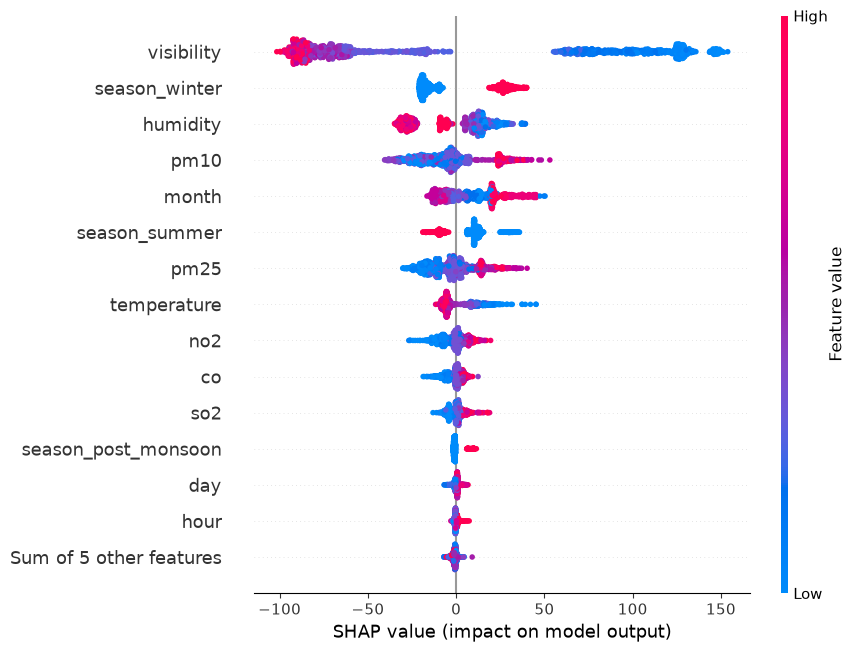

In [3]:
# ============================================================
# SHAP Beeswarm — 10% Mean
# ============================================================

shap.plots.beeswarm(
    shap_values_10_mean,
    max_display=15
)

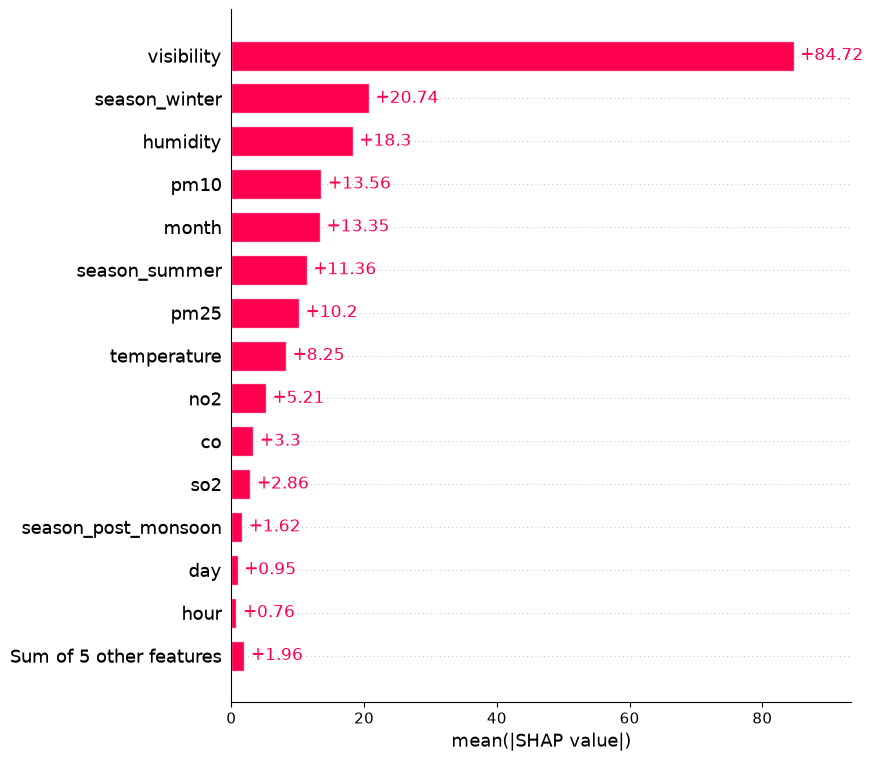

In [4]:
# ============================================================
# SHAP Feature Importance — 10% Mean
# ============================================================

shap.plots.bar(
    shap_values_10_mean,
    max_display=15
)

In [5]:
# ============================================================
# SHAP Feature Importance Table — 10% Mean
# ============================================================

shap_importance_10_mean = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(
        shap_values_10_mean.values
    ).mean(axis=0)
})

total_shap = shap_importance_10_mean["Mean_Absolute_SHAP"].sum()

shap_importance_10_mean["Importance_%"] = (
    shap_importance_10_mean["Mean_Absolute_SHAP"] /
    total_shap
) * 100

shap_importance_10_mean = (
    shap_importance_10_mean
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

shap_importance_10_mean.index += 1

shap_importance_10_mean

,Feature,Mean_Absolute_SHAP,Importance_%
1,visibility,84.720764,42.972435
2,season_winter,20.741453,10.520569
3,humidity,18.297913,9.281147
4,pm10,13.563265,6.879618
5,month,13.353701,6.773322
6,season_summer,11.361092,5.762622
7,pm25,10.203402,5.175414
8,temperature,8.247114,4.183137
9,no2,5.213224,2.644274
10,co,3.298812,1.673238


In [55]:
# ============================================================
# XGBoost — 30% Median Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(f"{DATA_DIR}/AQI_30pct_Median.csv")
df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("30% MEDIAN IMPUTATION — DATASET")
print("=" * 55)
print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_median = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_median.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_median = model_median.predict(X_test)

print("Predictions generated:", len(y_pred_median))

# 8. Measurements
mae_median = mean_absolute_error(
    y_test,
    y_pred_median
)

rmse_median = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_median
    )
)

r2_median = r2_score(
    y_test,
    y_pred_median
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 30% Median Imputation Results")
print("=" * 55)

print(f"MAE  : {mae_median:.4f}")
print(f"RMSE : {rmse_median:.4f}")
print(f"R²   : {r2_median:.4f}")

30% MEDIAN IMPUTATION — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 30% Median Imputation Results
MAE  : 6.3623
RMSE : 11.8705
R²   : 0.9950


In [56]:
# ============================================================
# XGBoost — 30% Forward Fill Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(f"{DATA_DIR}/AQI_30pct_ForwardFill.csv")
df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("30% FORWARD FILL — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_ff = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_ff.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_ff = model_ff.predict(X_test)

print("Predictions generated:", len(y_pred_ff))

# 8. Measurements
mae_ff = mean_absolute_error(
    y_test,
    y_pred_ff
)

rmse_ff = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_ff
    )
)

r2_ff = r2_score(
    y_test,
    y_pred_ff
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 30% Forward Fill Results")
print("=" * 55)

print(f"MAE  : {mae_ff:.4f}")
print(f"RMSE : {rmse_ff:.4f}")
print(f"R²   : {r2_ff:.4f}")

30% FORWARD FILL — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 30% Forward Fill Results
MAE  : 10.1538
RMSE : 16.6770
R²   : 0.9902


In [57]:
# ============================================================
# XGBoost — 30% Linear Interpolation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(
    f"{DATA_DIR}/AQI_30pct_LinearInterpolation.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("30% LINEAR INTERPOLATION — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_linear = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_linear.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_linear = model_linear.predict(X_test)

print("Predictions generated:", len(y_pred_linear))

# 8. Measurements
mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 30% Linear Interpolation Results")
print("=" * 55)

print(f"MAE  : {mae_linear:.4f}")
print(f"RMSE : {rmse_linear:.4f}")
print(f"R²   : {r2_linear:.4f}")

30% LINEAR INTERPOLATION — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 30% Linear Interpolation Results
MAE  : 9.5282
RMSE : 15.6055
R²   : 0.9914


In [58]:
# ============================================================
# XGBoost — 30% KNN Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(
    f"{DATA_DIR}/AQI_30pct_KNN.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("30% KNN — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_knn = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_knn.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_knn = model_knn.predict(X_test)

print("Predictions generated:", len(y_pred_knn))

# 8. Measurements
mae_knn = mean_absolute_error(
    y_test,
    y_pred_knn
)

rmse_knn = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_knn
    )
)

r2_knn = r2_score(
    y_test,
    y_pred_knn
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 30% KNN Results")
print("=" * 55)

print(f"MAE  : {mae_knn:.4f}")
print(f"RMSE : {rmse_knn:.4f}")
print(f"R²   : {r2_knn:.4f}")

30% KNN — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 30% KNN Results
MAE  : 8.5779
RMSE : 15.8790
R²   : 0.9911


In [59]:
# ============================================================
# XGBoost — 30% XGBoost Imputation
# Complete AQI Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# ------------------------------------------------------------
# 1. Load 30% XGBoost-imputed dataset
# ------------------------------------------------------------

df = pd.read_csv(
    f"{DATA_DIR}/AQI_30pct_XGBoost.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# ------------------------------------------------------------
# 2. Define target and features
# ------------------------------------------------------------

target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# ------------------------------------------------------------
# 3. Verify dataset
# ------------------------------------------------------------

print("=" * 60)
print("30% XGBOOST IMPUTATION — AQI MODEL")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Number of features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# Make sure everything used by XGBoost is numeric
non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()

print("Non-numeric features:", non_numeric)

if non_numeric:
    raise ValueError(
        f"Non-numeric columns found: {non_numeric}"
    )

# ------------------------------------------------------------
# 4. 2020–2024 → Training
#    2025 → Testing
# ------------------------------------------------------------

train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining period:")
print(df.loc[train_mask, "datetime"].min())
print("to")
print(df.loc[train_mask, "datetime"].max())

print("\nTesting period:")
print(df.loc[test_mask, "datetime"].min())
print("to")
print(df.loc[test_mask, "datetime"].max())

# ------------------------------------------------------------
# 5. Create XGBoost AQI prediction model
# ------------------------------------------------------------

model_xgb_imp = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 6. Train
# ------------------------------------------------------------

model_xgb_imp.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# ------------------------------------------------------------
# 7. Predict 2025 AQI
# ------------------------------------------------------------

y_pred_xgb_imp = model_xgb_imp.predict(X_test)

print("Predictions generated:", len(y_pred_xgb_imp))

# ------------------------------------------------------------
# 8. Measurements
# ------------------------------------------------------------

mae_xgb_imp = mean_absolute_error(
    y_test,
    y_pred_xgb_imp
)

rmse_xgb_imp = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb_imp
    )
)

r2_xgb_imp = r2_score(
    y_test,
    y_pred_xgb_imp
)

# ------------------------------------------------------------
# 9. Final results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("XGBoost — 30% XGBoost Imputation Results")
print("=" * 60)

print(f"MAE  : {mae_xgb_imp:.4f}")
print(f"RMSE : {rmse_xgb_imp:.4f}")
print(f"R²   : {r2_xgb_imp:.4f}")

30% XGBOOST IMPUTATION — AQI MODEL
Dataset shape: (8768, 22)
Number of features: 19
Missing feature values: 0
Non-numeric features: []

Training samples: 7308
Testing samples : 1460

Training period:
2020-01-01 06:00:00
to
2024-12-31 23:00:00

Testing period:
2025-01-01 06:00:00
to
2025-12-31 23:00:00

XGBoost training completed.
Predictions generated: 1460

XGBoost — 30% XGBoost Imputation Results
MAE  : 6.9676
RMSE : 13.6533
R²   : 0.9934


In [60]:
print("Mean Imputation")
print(f"MAE  : {mae_mean:.4f}")
print(f"RMSE : {rmse_mean:.4f}")
print(f"R²   : {r2_mean:.4f}")

print("\nMedian Imputation")
print(f"MAE  : {mae_median:.4f}")
print(f"RMSE : {rmse_median:.4f}")
print(f"R²   : {r2_median:.4f}")

print("\nForward Fill")
print(f"MAE  : {mae_ff:.4f}")
print(f"RMSE : {rmse_ff:.4f}")
print(f"R²   : {r2_ff:.4f}")

print("\nLinear Interpolation")
print(f"MAE  : {mae_linear:.4f}")
print(f"RMSE : {rmse_linear:.4f}")
print(f"R²   : {r2_linear:.4f}")

print("\nKNN Imputation")
print(f"MAE  : {mae_knn:.4f}")
print(f"RMSE : {rmse_knn:.4f}")
print(f"R²   : {r2_knn:.4f}")

print("\nXGBoost Imputation")
print(f"MAE  : {mae_xgb_imp:.4f}")
print(f"RMSE : {rmse_xgb_imp:.4f}")
print(f"R²   : {r2_xgb_imp:.4f}")

Mean Imputation
MAE  : 6.1867
RMSE : 11.8710
R²   : 0.9950

Median Imputation
MAE  : 6.3623
RMSE : 11.8705
R²   : 0.9950

Forward Fill
MAE  : 10.1538
RMSE : 16.6770
R²   : 0.9902

Linear Interpolation
MAE  : 9.5282
RMSE : 15.6055
R²   : 0.9914

KNN Imputation
MAE  : 8.5779
RMSE : 15.8790
R²   : 0.9911

XGBoost Imputation
MAE  : 6.9676
RMSE : 13.6533
R²   : 0.9934
